In [1]:
!pip install plotly


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option('display.max_columns', None)

In [5]:
path2 = r"C:\Users\Pichau\Documents\Github\Scripts_Python_PosEngDeDados\Data Visualization\Dataset\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv"

In [6]:
df = pd.read_csv(path2)
colunas = ['idade', 'horas_sono', 'descansou?','tempo_tela_diariamente','usou_antes_de_dormir', 'nivel_stress', 'ansiedade_ou_desanimo', 'aplicativos_bem_estar', 'qualidade_sono', 'tela_afetou_sono?']
df.columns = colunas

In [7]:
trad_tela_afetou_sono = {
    'Yes':'Sim',
    'No': 'Não',
    'Not Sure': 'incerto'
}

In [8]:
df['tela_afetou_sono?'] = df['tela_afetou_sono?'].map(trad_tela_afetou_sono)

In [9]:
faixa = [15,25,35,45,55]
labels = ['15-25','25-35','35-45','45-55']

df['faixa_etaria'] = pd.cut(
    df['idade'],
    bins=faixa,
    labels=labels
)

In [10]:
df.head()

,idade,horas_sono,descansou?,tempo_tela_diariamente,usou_antes_de_dormir,nivel_stress,ansiedade_ou_desanimo,aplicativos_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria
0,47,4,Yes,11,Yes,10,No,No,Bad,Sim,45-55
1,48,4,No,8,No,7,Yes,Yes,Bad,Sim,45-55
2,40,7,Sometimes,10,No,4,No,Yes,Bad,Sim,35-45
3,26,10,Yes,5,Yes,1,Yes,No,Good,Não,25-35
4,47,5,Yes,7,Yes,7,Yes,No,Good,Sim,45-55


<Axes: ylabel='count'>

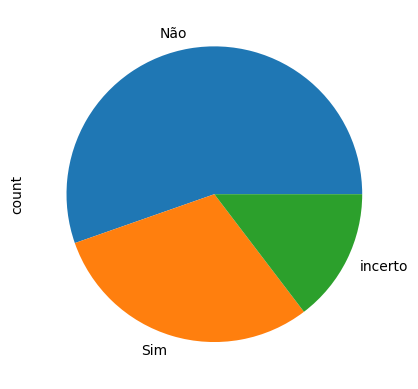

In [11]:
df['tela_afetou_sono?'].value_counts().plot(kind='pie')

In [12]:
pd.crosstab(df['faixa_etaria'], df['tela_afetou_sono?'])

tela_afetou_sono?,Não,Sim,incerto
faixa_etaria,,,
15-25,160,76,44
25-35,137,78,30
35-45,149,88,43
45-55,142,81,38


In [13]:
# 1. Instalação forçada no ambiente que está rodando agora
import sys
!{sys.executable} -m pip install --upgrade nbformat

# 2. Verificação (para termos certeza que funcionou)
import nbformat
print(f"Versão do nbformat instalada: {nbformat.__version__}")


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Versão do nbformat instalada: 5.10.4


In [14]:
px.histogram(data_frame=df, x='tela_afetou_sono?', text_auto=True, color='usou_antes_de_dormir', barmode='group')

In [15]:
px.histogram(data_frame=df, x='faixa_etaria', text_auto=True, color='qualidade_sono', barmode='group')

In [16]:
df.groupby(['qualidade_sono']).agg(tempo_tela_total=('tempo_tela_diariamente', 'sum'))

,tempo_tela_total
qualidade_sono,
Bad,3364
Good,3664


In [17]:
df['descansou?'].unique()

array(['Yes', 'No', 'Sometimes'], dtype=object)

<h2>Dicionario das variaveis</h2>

- idade = Idade dos entrevistados
- horas = tempo de sono em horas
- descansou = flag que diz se entrevistado conseguiu descansar durante o sono ou nao, contendo as informaçoes Sim, Nao, As Vezes
- tempo_tela_diariamente = o tempo de etla em horas que o individuo constuma ficar diariamente
- usou_antes_de_dormir = uma flag que diz se o individuo usou tela antes de dormir
- nivel_stress = um indicador de 1 a 10 para representar o nivel de stress do individuo
- ansiedade_ou_desanimo = um flag que diz se o individuo se sente ansioso ou desanimado
- aplicativos_bem_estar = uma flag para dizer se o individuo faz uso de aplicativos de bem estar
- qualidade_sono = um indicador que mostra como esta a qualidade do sono daquele individuo
- tela_afetou_sono? = uma flag que contem a informacao de sim ou nao para a tela ter afetado o sono

In [18]:
df.head()

,idade,horas_sono,descansou?,tempo_tela_diariamente,usou_antes_de_dormir,nivel_stress,ansiedade_ou_desanimo,aplicativos_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria
0,47,4,Yes,11,Yes,10,No,No,Bad,Sim,45-55
1,48,4,No,8,No,7,Yes,Yes,Bad,Sim,45-55
2,40,7,Sometimes,10,No,4,No,Yes,Bad,Sim,35-45
3,26,10,Yes,5,Yes,1,Yes,No,Good,Não,25-35
4,47,5,Yes,7,Yes,7,Yes,No,Good,Sim,45-55


In [19]:
df.describe()

,idade,horas_sono,tempo_tela_diariamente,nivel_stress
count,1100.000000,1100.000000,1100.000000,1100.000000
mean,34.813636,6.911818,6.389091,5.160909
std,11.990320,1.983197,2.650986,2.317501
min,15.000000,4.000000,2.000000,1.000000
25%,24.000000,5.000000,4.000000,3.000000
50%,35.000000,7.000000,6.000000,5.000000
75%,45.000000,9.000000,8.000000,7.000000
max,55.000000,10.000000,12.000000,10.000000


<Axes: xlabel='idade', ylabel='Count'>

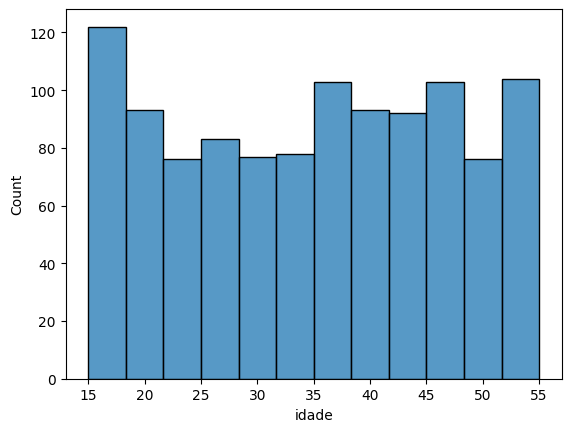

In [20]:
sns.histplot(df['idade'])

<Axes: >

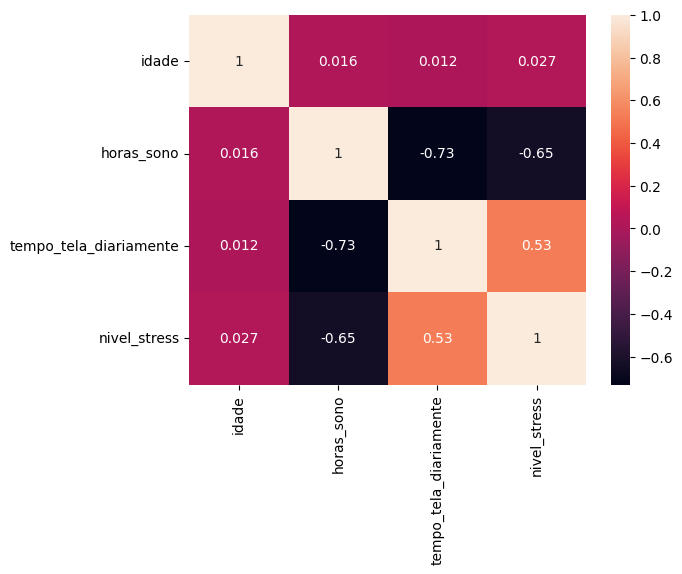

In [21]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [22]:
df.head()

,idade,horas_sono,descansou?,tempo_tela_diariamente,usou_antes_de_dormir,nivel_stress,ansiedade_ou_desanimo,aplicativos_bem_estar,qualidade_sono,tela_afetou_sono?,faixa_etaria
0,47,4,Yes,11,Yes,10,No,No,Bad,Sim,45-55
1,48,4,No,8,No,7,Yes,Yes,Bad,Sim,45-55
2,40,7,Sometimes,10,No,4,No,Yes,Bad,Sim,35-45
3,26,10,Yes,5,Yes,1,Yes,No,Good,Não,25-35
4,47,5,Yes,7,Yes,7,Yes,No,Good,Sim,45-55


In [23]:
df['']

KeyError: ''

In [ ]:
df.groupby(['faixa_etaria']).agg(tempo_total_tela=('tempo_tela_diariamente', 'sum')).sort_values(by='tempo_total_tela', ascending=False)

C:\Users\Pichau\AppData\Local\Temp\ipykernel_17068\2268977289.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['faixa_etaria']).agg(tempo_total_tela=('tempo_tela_diariamente', 'sum')).sort_values(by='tempo_total_tela', ascending=False)


,tempo_total_tela
faixa_etaria,
35-45,1817
15-25,1762
45-55,1658
25-35,1585


<Axes: >

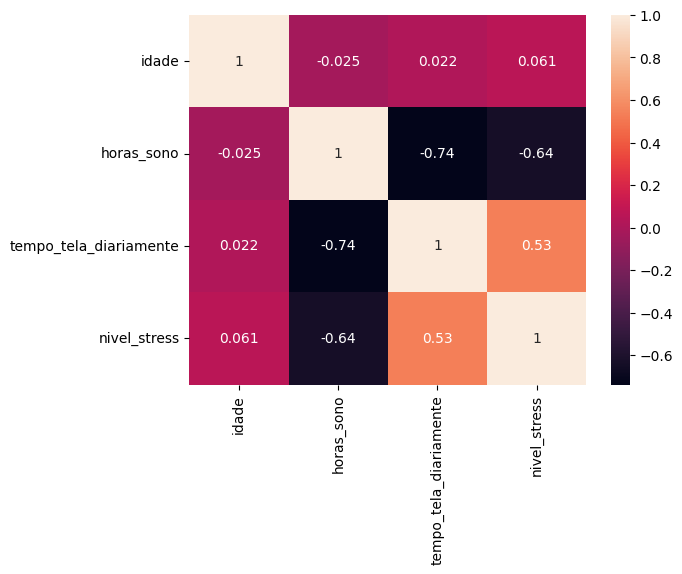

In [ ]:
sns.heatmap(df.query('faixa_etaria == "35-45"').corr(numeric_only=True), annot=True)

<Axes: >

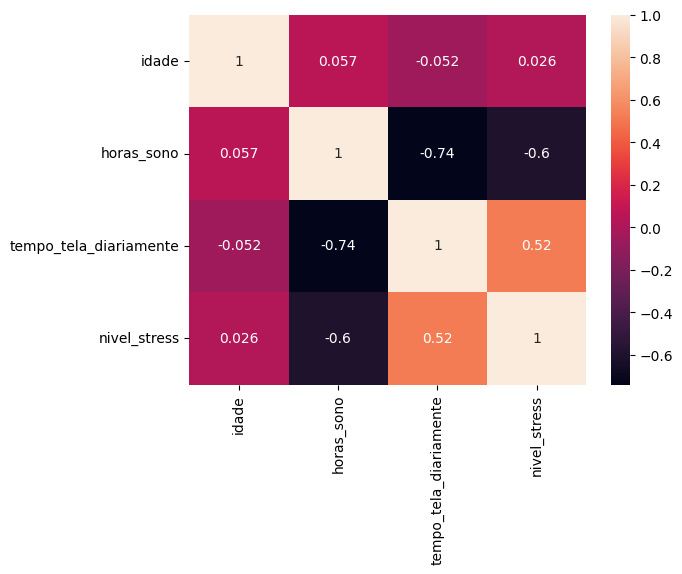

In [ ]:
sns.heatmap(df.query(f'faixa_etaria == "15-25"').corr(numeric_only=True), annot=True)

c:\Users\Pichau\Documents\Github\.venv\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
c:\Users\Pichau\Documents\Github\.venv\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


<Axes: >

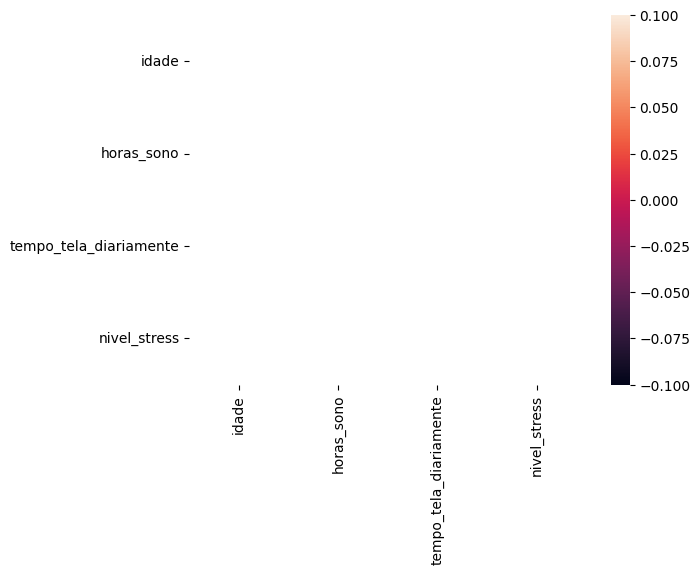

In [ ]:
sns.heatmap(df.query(f'faixa_etaria == ""').corr(numeric_only=True), annot=True)

In [ ]:
['15-25','25-35','35-45','45-55']

['15-25', '25-35', '35-45', '45-55']

<Axes: xlabel='horas_sono', ylabel='tempo_tela_diariamente'>

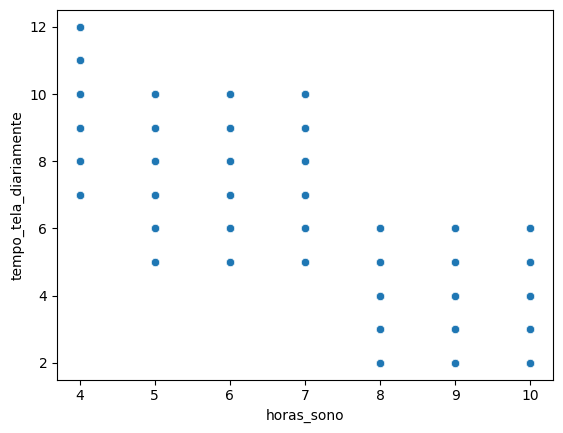

In [ ]:
sns.scatterplot(data=df, x='horas_sono', y='tempo_tela_diariamente')

<Axes: xlabel='horas_sono', ylabel='nivel_stress'>

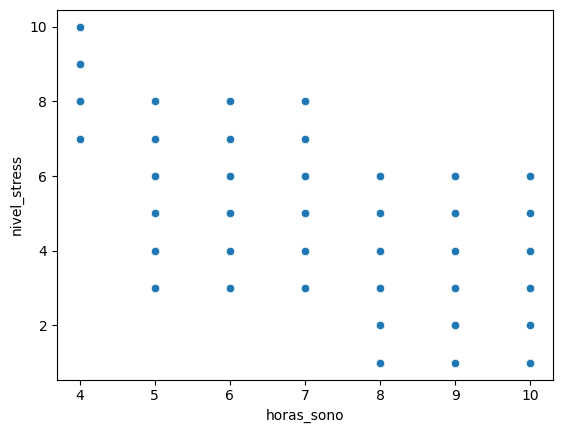

In [ ]:
sns.scatterplot(data=df, x='horas_sono', y='nivel_stress')

<Axes: xlabel='idade', ylabel='nivel_stress'>

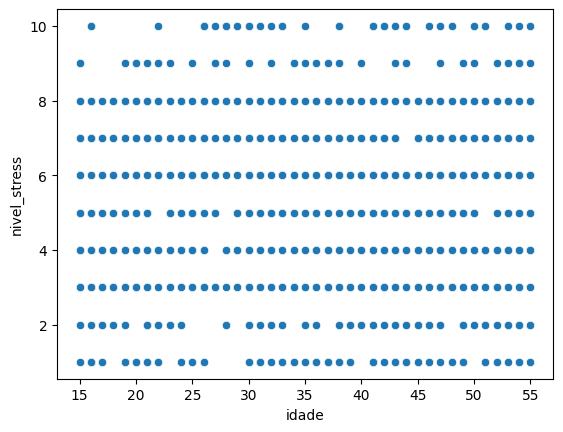

In [ ]:
sns.scatterplot(data=df, x='idade', y='nivel_stress')

# VALTAIR

In [ ]:
fig1 = px.scatter(df, 
                 x='tempo_tela_diariamente', 
                 y='nivel_stress', 
                 color='qualidade_sono',
                 size='nivel_stress',
                 title='Impacto do Tempo de Tela no Estresse e Qualidade do Sono',
                 labels={'tempo_tela_diariamente': 'Tempo de Tela (h)', 'nivel_stress': 'Nível de Estresse'})
fig1.show()

In [ ]:
# Criando faixas etárias
bins = [0, 15, 25, 40, 60, 100]
labels = ['Sub-15', '15-25', '26-40', '41-60', '60+']
df['faixa_etaria'] = pd.cut(df['idade'], bins=bins, labels=labels)

fig2 = px.box(df, 
             x='faixa_etaria', 
             y='nivel_stress', 
             color='qualidade_sono',
             title='Distribuição de Estresse e Sono por Faixa Etária',
             points="all")
fig2.show()

In [ ]:
fig3 = px.scatter(df, 
                 x='tempo_tela_diariamente', 
                 y='horas_sono', 
                 trendline="ols", 
                 title='Correlação: Tempo de Tela Diário vs. Horas de Sono',
                 labels={'horas_sono': 'Horas de Sono', 'tempo_tela_diariamente': 'Tempo de Tela (h)'})
fig3.show()

In [ ]:
fig4 = px.density_heatmap(df, 
                         x='horas_sono', 
                         y='nivel_stress', 
                         text_auto=True,
                         title='Concentração: Horas de Sono vs. Nível de Estresse',
                         color_continuous_scale='Viridis',
                         labels={'horas_sono': 'Horas de Sono', 'nivel_stress': 'Nível de Estresse'})
fig4.show()

In [ ]:
fig5 = px.histogram(df, 
                   x='usou_antes_de_dormir', 
                   y='nivel_stress', 
                   color='tela_afetou_sono?', 
                   barmode='group',
                   histfunc='avg',
                   title='Média de Estresse: Uso de Tela Antes de Dormir vs. Percepção de Impacto')
fig5.show()

In [ ]:
fig6 = px.violin(df, 
                y='tempo_tela_diariamente', 
                x='ansiedade_ou_desanimo', 
                color='ansiedade_ou_desanimo', 
                box=True, 
                points="all",
                title='Distribuição do Tempo de Tela por Estado de Ansiedade/Desânimo')
fig6.show()

In [ ]:
fig_descanso = px.box(df, 
                     x='descansou?', 
                     y='nivel_stress', 
                     color='descansou?',
                     title='Impacto de Sentir-se Descansado no Nível de Estresse')
fig_descanso.show()

In [ ]:
fig7 = px.histogram(df, 
                   x='ansiedade_ou_desanimo', 
                   color='qualidade_sono', 
                   barnorm='percent',
                   title='Proporção da Qualidade do Sono por Estado de Ansiedade')
fig7.show()

________________________________________________________________________________________________________________________________________________________________________________________

09/04/2026